In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [2]:
# Step 3.8 Part A — Project paths

project_root = Path.cwd()

if not (project_root / "data" / "interim").is_dir():
    project_root = project_root.parent

interim_path = project_root / "data" / "interim"
figures_path = project_root / "reports" / "figures"

figures_path.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Interim data path:", interim_path)
print("Figures path:", figures_path)

assert interim_path.is_dir(), "Interim data folder not found!"

Project root: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics
Interim data path: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\data\interim
Figures path: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\figures


In [3]:
# Load all five cleaned datasets

datasets = {
    "plans": pd.read_csv(interim_path / "plans_cleaned.csv"),
    "customers": pd.read_csv(interim_path / "customers_cleaned.csv"),
    "subscriptions": pd.read_csv(
        interim_path / "subscriptions_cleaned.csv"
    ),
    "subscription_months": pd.read_csv(
        interim_path / "subscription_months_cleaned.csv"
    ),
    "invoices": pd.read_csv(interim_path / "invoices_cleaned.csv")
}

print("CLEANED DATASETS LOADED")
print("=" * 55)

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

CLEANED DATASETS LOADED
plans: 10 rows, 11 columns
customers: 1200 rows, 12 columns
subscriptions: 1381 rows, 12 columns
subscription_months: 19015 rows, 15 columns
invoices: 11257 rows, 17 columns


In [4]:
# EDA Dataset Overview

overview_results = []

for name, df in datasets.items():

    overview_results.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing_Values": int(df.isna().sum().sum()),
        "Duplicate_Rows": int(df.duplicated().sum())
    })

eda_overview = pd.DataFrame(overview_results)

print("EDA DATASET OVERVIEW")
print("=" * 75)

print(eda_overview.to_string(index=False))

print("\nTotal records:", eda_overview["Rows"].sum())
print("Total columns:", eda_overview["Columns"].sum())
print("Total missing values:", eda_overview["Missing_Values"].sum())

EDA DATASET OVERVIEW
            Dataset  Rows  Columns  Missing_Values  Duplicate_Rows
              plans    10       11               0               0
          customers  1200       12             855               0
      subscriptions  1381       12             855               0
subscription_months 19015       15               0               0
           invoices 11257       17             309               0

Total records: 32863
Total columns: 67
Total missing values: 2019


In [5]:
# Final EDA Setup Verification

assert len(datasets) == 5
assert eda_overview["Rows"].sum() == 32863
assert eda_overview["Columns"].sum() == 67
assert eda_overview["Missing_Values"].sum() == 2019
assert eda_overview["Duplicate_Rows"].sum() == 0

print("RESULT: PASS - EDA notebook setup verified.")

RESULT: PASS - EDA notebook setup verified.


In [6]:
# Step 3.8 Part B.1 — Parse date columns

date_columns = {
    "plans": ["launched_date"],
    "customers": [
        "signup_date",
        "churn_date",
        "cohort_month"
    ],
    "subscriptions": [
        "start_date",
        "end_date"
    ],
    "subscription_months": [
        "period_month",
        "month_start_date",
        "cohort_month"
    ],
    "invoices": [
        "invoice_date",
        "invoice_month",
        "billing_period_start",
        "billing_period_end"
    ]
}

date_results = []

for table_name, columns in date_columns.items():
    df = datasets[table_name]

    for column in columns:
        original = df[column]

        parsed = pd.to_datetime(
            original,
            format="%Y-%m-%d",
            errors="coerce"
        )

        invalid_dates = (
            original.notna() & parsed.isna()
        ).sum()

        df[column] = parsed

        date_results.append({
            "Dataset": table_name,
            "Column": column,
            "Invalid_Dates": int(invalid_dates),
            "Data_Type": str(df[column].dtype)
        })

date_validation = pd.DataFrame(date_results)

print("DATE CONVERSION SUMMARY")
print("=" * 80)
print(date_validation.to_string(index=False))

DATE CONVERSION SUMMARY
            Dataset               Column  Invalid_Dates      Data_Type
              plans        launched_date              0 datetime64[us]
          customers          signup_date              0 datetime64[us]
          customers           churn_date              0 datetime64[us]
          customers         cohort_month              0 datetime64[us]
      subscriptions           start_date              0 datetime64[us]
      subscriptions             end_date              0 datetime64[us]
subscription_months         period_month              0 datetime64[us]
subscription_months     month_start_date              0 datetime64[us]
subscription_months         cohort_month              0 datetime64[us]
           invoices         invoice_date              0 datetime64[us]
           invoices        invoice_month              0 datetime64[us]
           invoices billing_period_start              0 datetime64[us]
           invoices   billing_period_end             

In [7]:
# Step 3.8 Part B.2 — Date range inspection

date_range_results = []

for table_name, columns in date_columns.items():
    df = datasets[table_name]

    for column in columns:
        date_range_results.append({
            "Dataset": table_name,
            "Column": column,
            "Earliest_Date": df[column].min(),
            "Latest_Date": df[column].max(),
            "Missing_Values": int(df[column].isna().sum())
        })

date_range_summary = pd.DataFrame(date_range_results)

print("DATASET DATE COVERAGE")
print("=" * 95)

print(date_range_summary.to_string(index=False))

DATASET DATE COVERAGE
            Dataset               Column Earliest_Date Latest_Date  Missing_Values
              plans        launched_date    2021-01-15  2023-01-15               0
          customers          signup_date    2021-01-05  2026-06-30               0
          customers           churn_date    2024-02-01  2026-06-01             855
          customers         cohort_month    2024-01-01  2026-06-01               0
      subscriptions           start_date    2021-01-05  2026-06-30               0
      subscriptions             end_date    2024-01-31  2026-06-01             855
subscription_months         period_month    2024-01-01  2026-06-01               0
subscription_months     month_start_date    2024-01-01  2026-06-01               0
subscription_months         cohort_month    2024-01-01  2026-06-01               0
           invoices         invoice_date    2024-01-01  2026-06-05               0
           invoices        invoice_month    2024-01-01  2026-06-0

In [8]:
# Step 3.8 Part B.3 — Monthly subscription coverage

monthly_df = datasets["subscription_months"]

monthly_coverage = (
    monthly_df["period_month"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("MONTHLY SUBSCRIPTION DATA COVERAGE")
print("=" * 65)

print(monthly_coverage.to_string())

print("\nFirst month:", monthly_coverage.index.min())
print("Last month:", monthly_coverage.index.max())
print("Months represented:", len(monthly_coverage))
print("Total monthly records:", monthly_coverage.sum())

MONTHLY SUBSCRIPTION DATA COVERAGE
period_month
2024-01    464
2024-02    481
2024-03    477
2024-04    477
2024-05    486
2024-06    489
2024-07    495
2024-08    503
2024-09    523
2024-10    527
2024-11    544
2024-12    562
2025-01    584
2025-02    593
2025-03    604
2025-04    623
2025-05    646
2025-06    667
2025-07    677
2025-08    694
2025-09    705
2025-10    728
2025-11    748
2025-12    767
2026-01    778
2026-02    802
2026-03    815
2026-04    837
2026-05    845
2026-06    874
Freq: M

First month: 2024-01
Last month: 2026-06
Months represented: 30
Total monthly records: 19015


In [9]:
# Step 3.8 Part B.4 — Missing calendar months

first_month = monthly_coverage.index.min()
last_month = monthly_coverage.index.max()

expected_months = pd.period_range(
    start=first_month,
    end=last_month,
    freq="M"
)

missing_months = expected_months.difference(
    monthly_coverage.index
)

print("MONTHLY TIMELINE VALIDATION")
print("=" * 60)

print("Expected calendar months:", len(expected_months))
print("Observed calendar months:", len(monthly_coverage))
print("Missing calendar months:", len(missing_months))

if len(missing_months) == 0:
    print("RESULT: PASS - No missing calendar months.")
else:
    print("RESULT: REVIEW REQUIRED")
    print("Missing months:", missing_months.tolist())

MONTHLY TIMELINE VALIDATION
Expected calendar months: 30
Observed calendar months: 30
Missing calendar months: 0
RESULT: PASS - No missing calendar months.


In [10]:
# Step 3.8 Part B.5 — Final checks

dates_pass = (
    len(date_validation) == 13
    and date_validation["Invalid_Dates"].sum() == 0
)

records_pass = monthly_coverage.sum() == 19015

timeline_pass = len(missing_months) == 0

print("EDA DATE PREPARATION VALIDATION")
print("=" * 60)

print("All 13 date columns valid:", dates_pass)
print("Monthly record count correct:", records_pass)
print("No missing calendar months:", timeline_pass)

if dates_pass and records_pass and timeline_pass:
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

EDA DATE PREPARATION VALIDATION
All 13 date columns valid: True
Monthly record count correct: True
No missing calendar months: True

RESULT: PASS


In [11]:
# Step 3.8 Part C.1 — Customer Status Distribution

customers_df = datasets["customers"]

customer_status = (
    customers_df["customer_status"]
    .value_counts(dropna=False)
    .rename_axis("Customer_Status")
    .reset_index(name="Customer_Count")
)

customer_status["Percentage"] = (
    customer_status["Customer_Count"]
    / len(customers_df) * 100
).round(2)

print("CUSTOMER STATUS DISTRIBUTION")
print("=" * 60)
print(customer_status.to_string(index=False))

CUSTOMER STATUS DISTRIBUTION
Customer_Status  Customer_Count  Percentage
         Active             855       71.25
        Churned             345       28.75


In [12]:
# Step 3.8 Part C.2 — Subscription Status Distribution

subscriptions_df = datasets["subscriptions"]

subscription_status = (
    subscriptions_df["subscription_status"]
    .value_counts(dropna=False)
    .rename_axis("Subscription_Status")
    .reset_index(name="Subscription_Count")
)

subscription_status["Percentage"] = (
    subscription_status["Subscription_Count"]
    / len(subscriptions_df) * 100
).round(2)

print("SUBSCRIPTION STATUS DISTRIBUTION")
print("=" * 65)
print(subscription_status.to_string(index=False))

SUBSCRIPTION STATUS DISTRIBUTION
Subscription_Status  Subscription_Count  Percentage
             Active                 855       61.91
            Churned                 368       26.65
           Upgraded                 115        8.33
         Downgraded                  43        3.11


In [13]:
# Step 3.8 Part C.3 — Subscription Distribution by Plan

plan_distribution = (
    subscriptions_df["plan_id"]
    .value_counts(dropna=False)
    .rename_axis("Plan_ID")
    .reset_index(name="Subscription_Count")
)

plan_distribution["Percentage"] = (
    plan_distribution["Subscription_Count"]
    / len(subscriptions_df) * 100
).round(2)

print("SUBSCRIPTION DISTRIBUTION BY PLAN")
print("=" * 65)
print(plan_distribution.to_string(index=False))

SUBSCRIPTION DISTRIBUTION BY PLAN
Plan_ID  Subscription_Count  Percentage
 PLN-03                 367       26.57
 PLN-01                 298       21.58
 PLN-04                 173       12.53
 PLN-05                 168       12.17
 PLN-06                 157       11.37
 PLN-02                  81        5.87
 PLN-07                  47        3.40
 PLN-08                  45        3.26
 PLN-10                  25        1.81
 PLN-09                  20        1.45


In [14]:
# Step 3.8 Part C.4 — Movement Type Distribution

monthly_df = datasets["subscription_months"]

movement_distribution = (
    monthly_df["movement_type"]
    .value_counts(dropna=False)
    .rename_axis("Movement_Type")
    .reset_index(name="Record_Count")
)

movement_distribution["Percentage"] = (
    movement_distribution["Record_Count"]
    / len(monthly_df) * 100
).round(2)

print("SUBSCRIPTION MOVEMENT DISTRIBUTION")
print("=" * 65)
print(movement_distribution.to_string(index=False))

SUBSCRIPTION MOVEMENT DISTRIBUTION
Movement_Type  Record_Count  Percentage
     Retained         16143       84.90
          New          1200        6.31
    Expansion          1023        5.38
        Churn           368        1.94
  Contraction           258        1.36
 Reactivation            23        0.12


In [15]:
# Step 3.8 Part C.5 — Descriptive Analysis Validation

customers_pass = (
    customer_status["Customer_Count"].sum() == 1200
)

subscriptions_pass = (
    subscription_status["Subscription_Count"].sum() == 1381
)

plans_pass = (
    plan_distribution["Subscription_Count"].sum() == 1381
)

movements_pass = (
    movement_distribution["Record_Count"].sum() == 19015
)

print("DESCRIPTIVE ANALYSIS VALIDATION")
print("=" * 60)

print("Customer distribution:", customers_pass)
print("Subscription distribution:", subscriptions_pass)
print("Plan distribution:", plans_pass)
print("Movement distribution:", movements_pass)

if all([
    customers_pass,
    subscriptions_pass,
    plans_pass,
    movements_pass
]):
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

DESCRIPTIVE ANALYSIS VALIDATION
Customer distribution: True
Subscription distribution: True
Plan distribution: True
Movement distribution: True

RESULT: PASS


In [16]:
# Step 3.8 Part D.1 — Visualization styling

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "savefig.dpi": 200
})

chart_colors = {
    "blue": "#2563EB",
    "green": "#10B981",
    "orange": "#F59E0B",
    "red": "#EF4444",
    "purple": "#8B5CF6",
    "teal": "#14B8A6"
}

print("Visualization styling configured successfully.")

Visualization styling configured successfully.


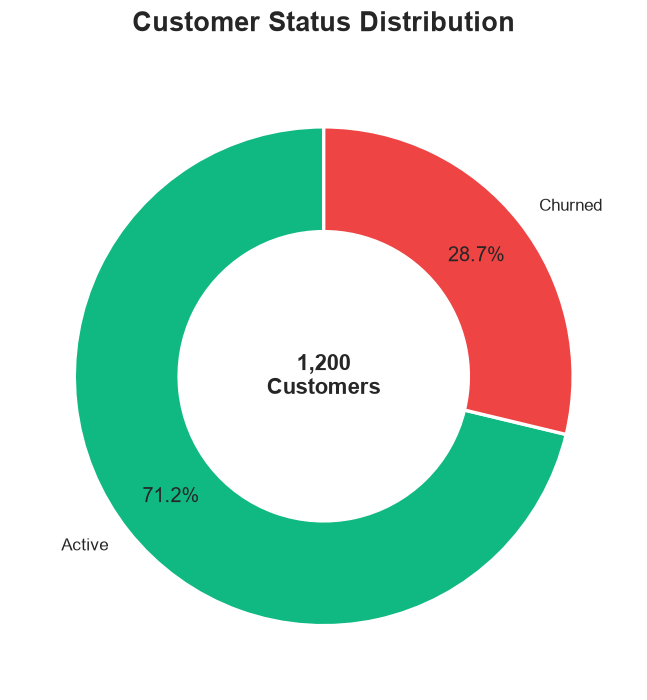

In [17]:
# Step 3.8 Part D.2 — Customer status doughnut chart

status_counts = (
    datasets["customers"]["customer_status"]
    .value_counts()
)

colors = [
    chart_colors["green"] if status == "Active"
    else chart_colors["red"]
    for status in status_counts.index
]

fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.42,
        "edgecolor": "white",
        "linewidth": 2
    }
)

ax.set_title(
    "Customer Status Distribution",
    pad=20
)

ax.text(
    0, 0,
    f"{status_counts.sum():,}\nCustomers",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    figures_path / "customer_status_distribution.png",
    bbox_inches="tight"
)

plt.show()

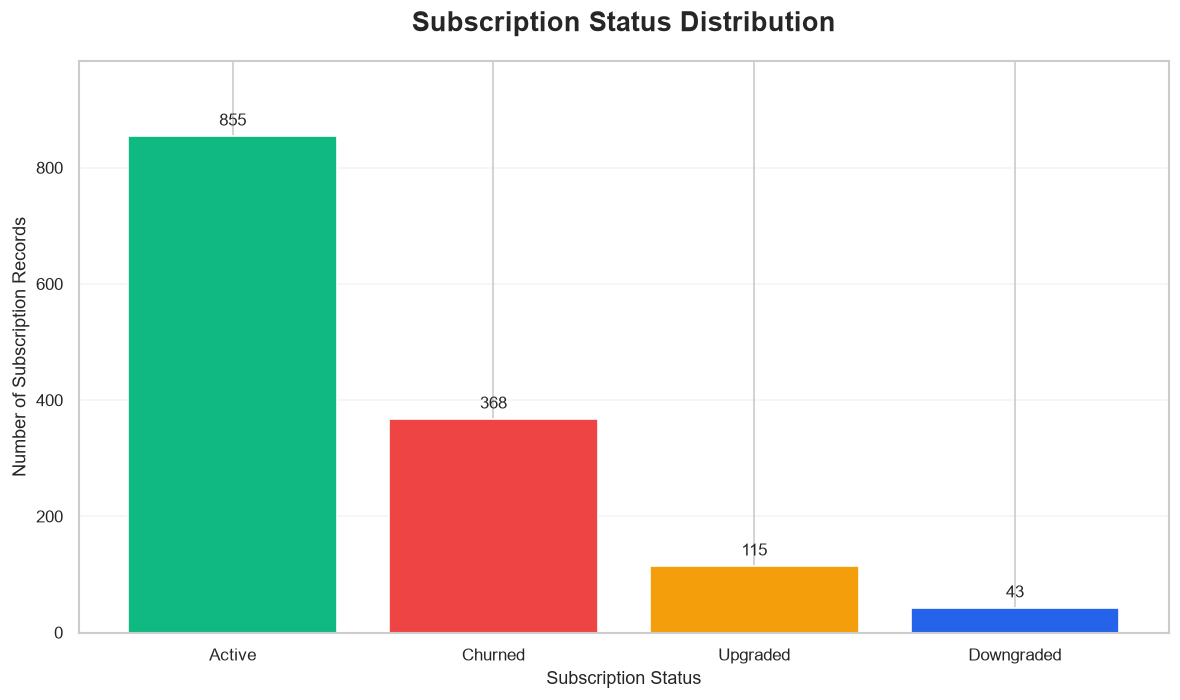

In [18]:
# Step 3.8 Part D.3 — Subscription status bar chart

status_data = (
    datasets["subscriptions"]["subscription_status"]
    .value_counts()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    status_data.index,
    status_data.values,
    color=[
        chart_colors["green"],
        chart_colors["red"],
        chart_colors["orange"],
        chart_colors["blue"]
    ]
)

ax.bar_label(bars, padding=4, fontsize=10)

ax.set_title("Subscription Status Distribution", pad=18)
ax.set_xlabel("Subscription Status")
ax.set_ylabel("Number of Subscription Records")

ax.set_ylim(0, status_data.max() * 1.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    figures_path / "subscription_status_distribution.png",
    bbox_inches="tight"
)

plt.show()

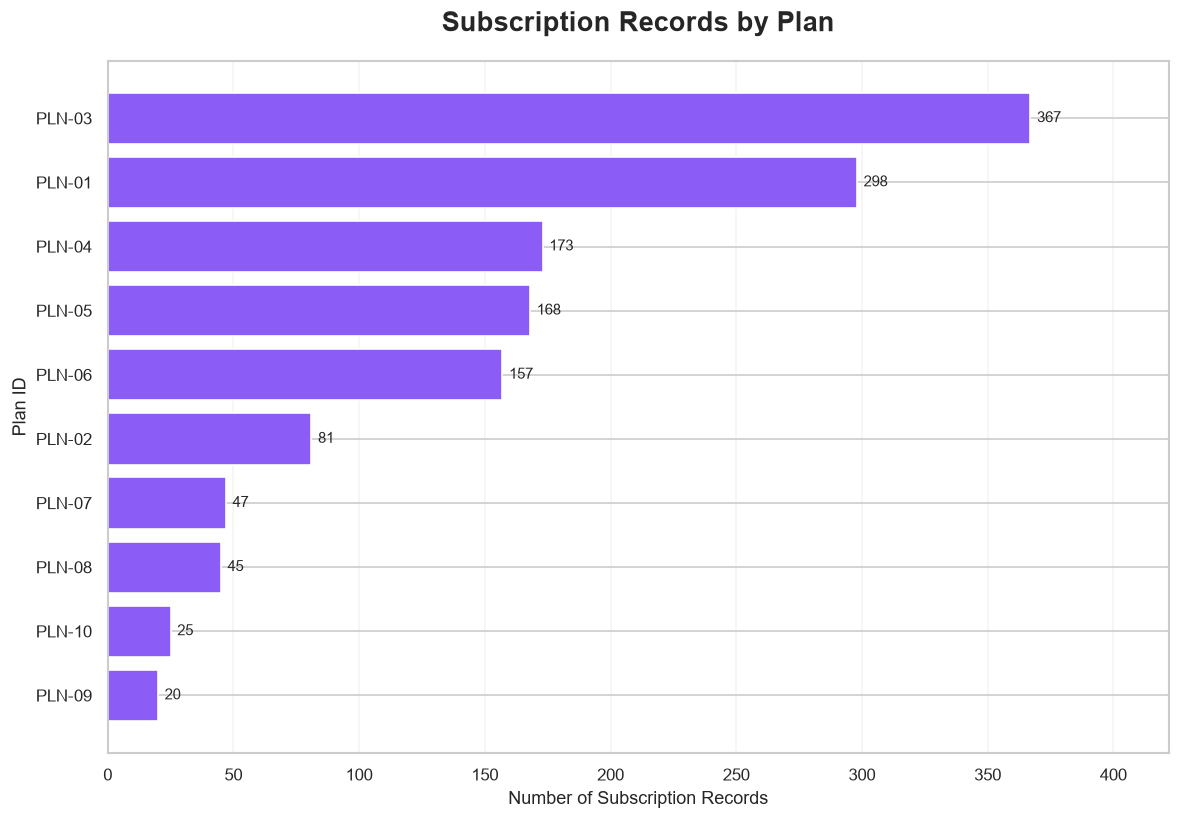

In [19]:
# Step 3.8 Part D.4 — Subscription distribution by plan

plan_counts = (
    datasets["subscriptions"]["plan_id"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    plan_counts.index.astype(str),
    plan_counts.values,
    color=chart_colors["purple"]
)

ax.bar_label(bars, padding=4, fontsize=9)

ax.set_title("Subscription Records by Plan", pad=18)
ax.set_xlabel("Number of Subscription Records")
ax.set_ylabel("Plan ID")

ax.set_xlim(0, plan_counts.max() * 1.15)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    figures_path / "subscription_distribution_by_plan.png",
    bbox_inches="tight"
)

plt.show()

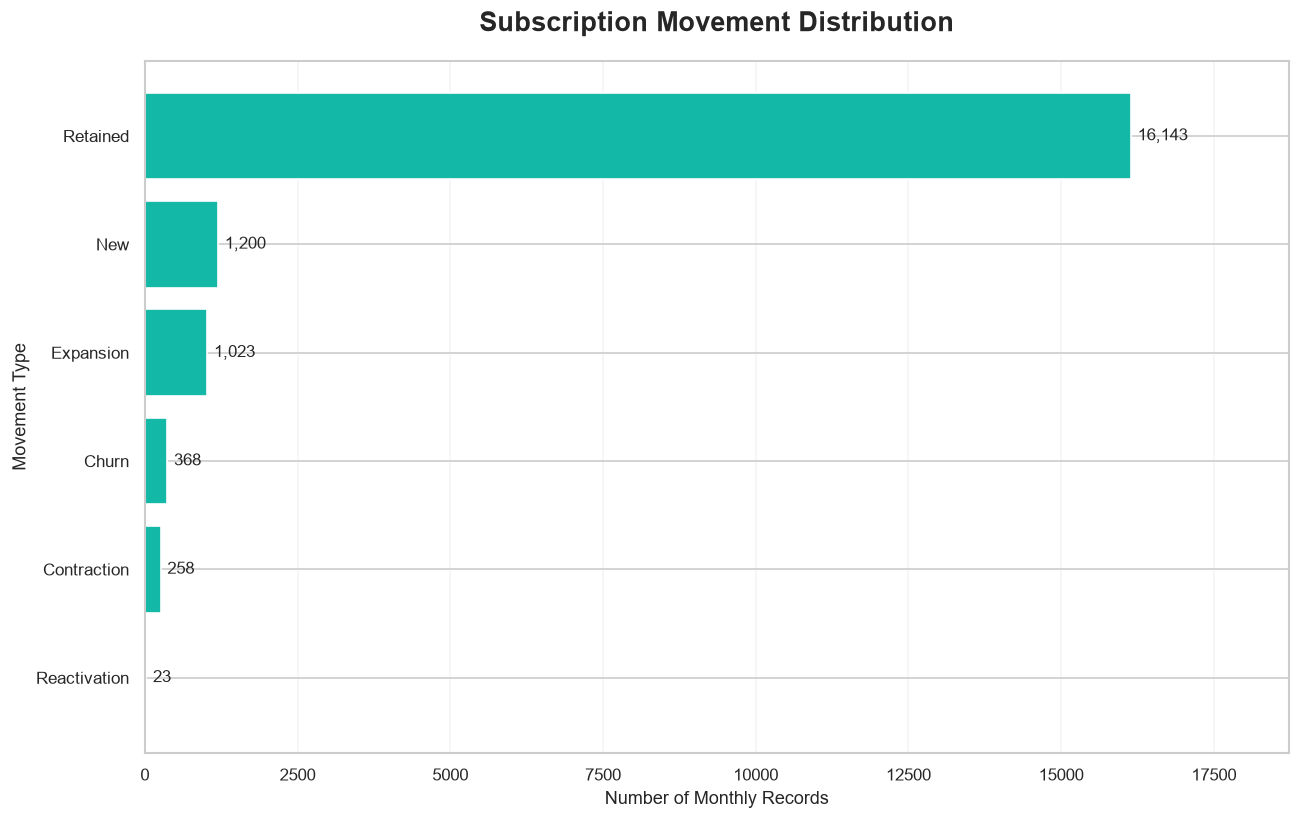

In [20]:
# Step 3.8 Part D.5 — Subscription movement distribution

movement_counts = (
    datasets["subscription_months"]["movement_type"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    movement_counts.index,
    movement_counts.values,
    color=chart_colors["teal"]
)

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in movement_counts.values],
    padding=4,
    fontsize=10
)

ax.set_title("Subscription Movement Distribution", pad=18)
ax.set_xlabel("Number of Monthly Records")
ax.set_ylabel("Movement Type")

ax.set_xlim(0, movement_counts.max() * 1.16)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    figures_path / "subscription_movement_distribution.png",
    bbox_inches="tight"
)

plt.show()

In [21]:
# Step 3.8 Part D.6 — Chart export verification

expected_charts = [
    "customer_status_distribution.png",
    "subscription_status_distribution.png",
    "subscription_distribution_by_plan.png",
    "subscription_movement_distribution.png"
]

print("EDA CHART EXPORT VERIFICATION")
print("=" * 65)

all_saved = True

for filename in expected_charts:
    file_path = figures_path / filename

    exists = file_path.is_file()
    nonempty = exists and file_path.stat().st_size > 0

    print(
        f"{filename}: "
        f"{'PASS' if nonempty else 'FAILED'}"
    )

    if not nonempty:
        all_saved = False

if all_saved:
    print("\nRESULT: PASS - All four EDA charts saved.")
else:
    print("\nRESULT: REVIEW REQUIRED")

EDA CHART EXPORT VERIFICATION
customer_status_distribution.png: PASS
subscription_status_distribution.png: PASS
subscription_distribution_by_plan.png: PASS
subscription_movement_distribution.png: PASS

RESULT: PASS - All four EDA charts saved.


In [22]:
# Step 3.8 Part E.1 — Prepare monthly subscription data

monthly_df = datasets["subscription_months"].copy()

monthly_df["analysis_month"] = (
    monthly_df["period_month"].dt.to_period("M")
)

print("MONTHLY DATA PREPARATION")
print("=" * 60)

print("Total records:", len(monthly_df))
print("First month:", monthly_df["analysis_month"].min())
print("Last month:", monthly_df["analysis_month"].max())
print("Unique months:", monthly_df["analysis_month"].nunique())

assert len(monthly_df) == 19015

print("\nRESULT: PASS")

MONTHLY DATA PREPARATION
Total records: 19015
First month: 2024-01
Last month: 2026-06
Unique months: 30

RESULT: PASS


In [23]:
# Step 3.8 Part E.2 — Monthly subscription activity

monthly_activity = (
    monthly_df
    .groupby("analysis_month")
    .agg(
        Monthly_Records=("subscription_id", "size"),
        Unique_Subscriptions=("subscription_id", "nunique"),
        Unique_Customers=("customer_id", "nunique")
    )
    .reset_index()
    .sort_values("analysis_month")
)

print("MONTHLY SUBSCRIPTION ACTIVITY")
print("=" * 80)

print(monthly_activity.to_string(index=False))

print("\nTotal monthly records:",
      monthly_activity["Monthly_Records"].sum())

MONTHLY SUBSCRIPTION ACTIVITY
analysis_month  Monthly_Records  Unique_Subscriptions  Unique_Customers
       2024-01              464                   464               464
       2024-02              481                   481               481
       2024-03              477                   477               477
       2024-04              477                   477               477
       2024-05              486                   486               486
       2024-06              489                   489               489
       2024-07              495                   495               495
       2024-08              503                   503               503
       2024-09              523                   523               523
       2024-10              527                   527               527
       2024-11              544                   544               544
       2024-12              562                   562               562
       2025-01              584   

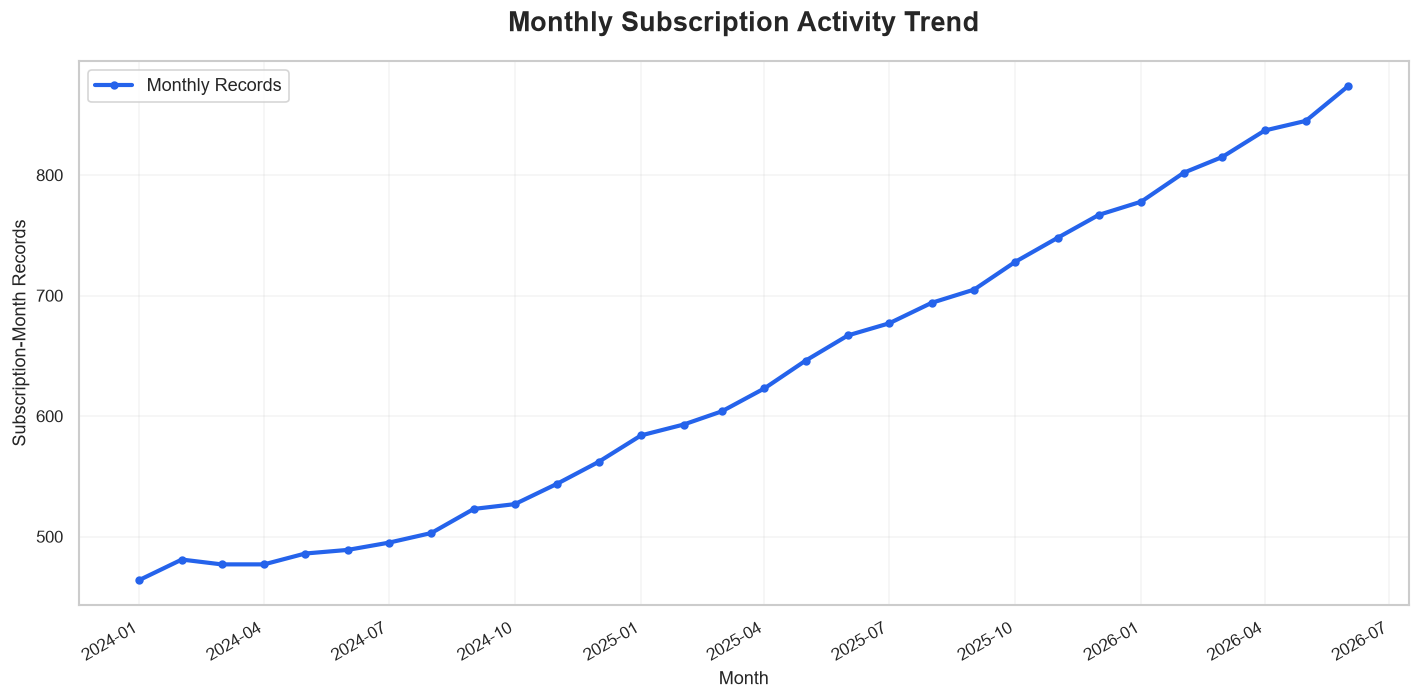

In [24]:
# Step 3.8 Part E.3 — Monthly subscription activity trend

plot_data = monthly_activity.copy()

plot_data["Month"] = (
    plot_data["analysis_month"].dt.to_timestamp()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    plot_data["Month"],
    plot_data["Monthly_Records"],
    marker="o",
    linewidth=2.5,
    markersize=4,
    color=chart_colors["blue"],
    label="Monthly Records"
)

ax.set_title(
    "Monthly Subscription Activity Trend",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Subscription-Month Records")

ax.grid(alpha=0.2)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()

plt.savefig(
    figures_path / "monthly_subscription_activity.png",
    bbox_inches="tight"
)

plt.show()

In [25]:
# Step 3.8 Part E.4 — Monthly movement counts

monthly_movements = pd.crosstab(
    monthly_df["analysis_month"],
    monthly_df["movement_type"]
)

movement_categories = [
    "New",
    "Retained",
    "Expansion",
    "Contraction",
    "Churn",
    "Reactivation"
]

monthly_movements = monthly_movements.reindex(
    columns=movement_categories,
    fill_value=0
)

monthly_movements = monthly_movements.sort_index()

print("MONTHLY SUBSCRIPTION MOVEMENTS")
print("=" * 100)

print(monthly_movements.to_string())

print("\nMovement totals:")
print(monthly_movements.sum().to_string())

MONTHLY SUBSCRIPTION MOVEMENTS
movement_type   New  Retained  Expansion  Contraction  Churn  Reactivation
analysis_month                                                            
2024-01         464         0          0            0      0             0
2024-02          17       418         25            8     13             0
2024-03           9       412         33            9     14             0
2024-04          14       410         33            8     12             0
2024-05          21       424         25            4     12             0
2024-06          14       423         36            6      9             1
2024-07          15       437         29            5      9             0
2024-08          16       444         28            6      8             1
2024-09          25       441         32            8     14             3
2024-10          18       456         34            5     14             0
2024-11          30       467         30            6     10         

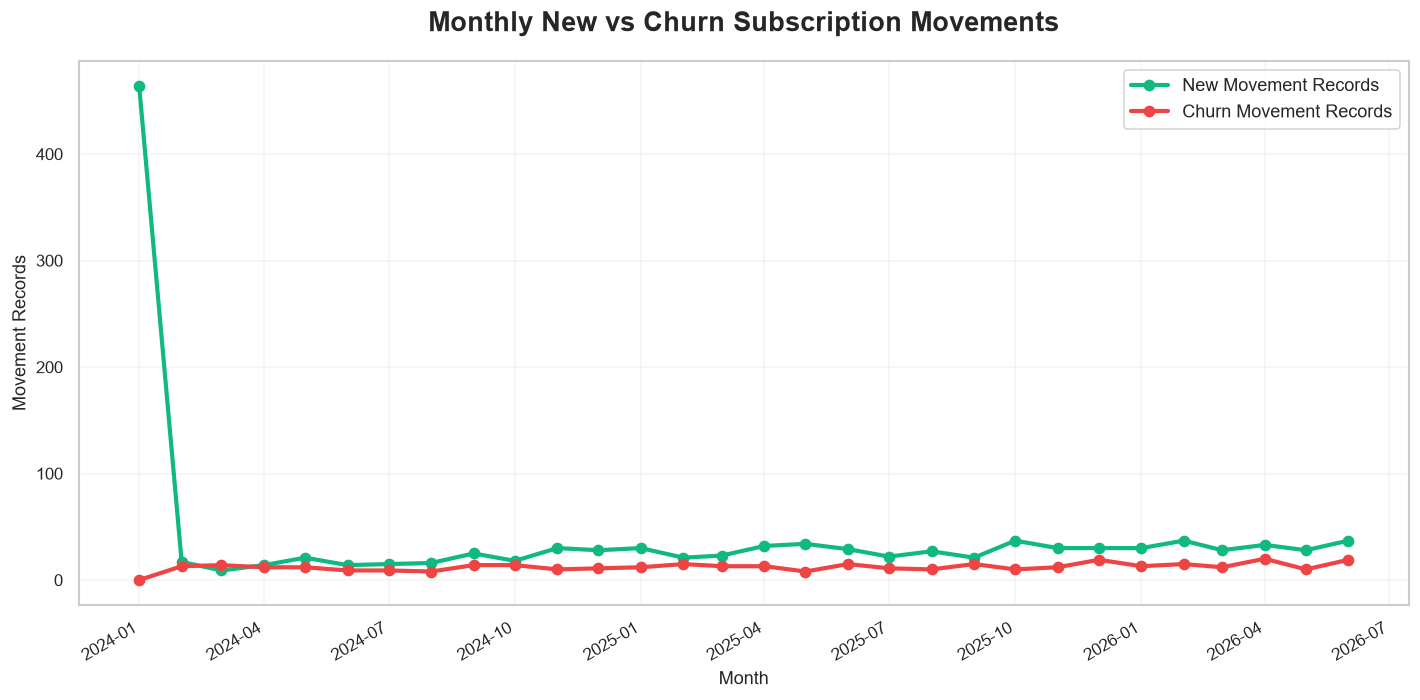

In [26]:
# Step 3.8 Part E.5 — New vs Churn movement trend

movement_plot = monthly_movements.copy()

movement_plot.index = (
    movement_plot.index.to_timestamp()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    movement_plot.index,
    movement_plot["New"],
    marker="o",
    linewidth=2.5,
    color=chart_colors["green"],
    label="New Movement Records"
)

ax.plot(
    movement_plot.index,
    movement_plot["Churn"],
    marker="o",
    linewidth=2.5,
    color=chart_colors["red"],
    label="Churn Movement Records"
)

ax.set_title(
    "Monthly New vs Churn Subscription Movements",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Movement Records")

ax.grid(alpha=0.2)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()

plt.savefig(
    figures_path / "monthly_new_vs_churn_movements.png",
    bbox_inches="tight"
)

plt.show()

In [27]:
# Step 3.8 Part E.6 — Monthly observations

highest_activity = monthly_activity.loc[
    monthly_activity["Monthly_Records"].idxmax()
]

lowest_activity = monthly_activity.loc[
    monthly_activity["Monthly_Records"].idxmin()
]

highest_new_month = monthly_movements["New"].idxmax()
highest_churn_month = monthly_movements["Churn"].idxmax()

print("MONTHLY SUBSCRIPTION FINDINGS")
print("=" * 70)

print(
    "Highest activity month:",
    highest_activity["analysis_month"],
    "| Records:",
    highest_activity["Monthly_Records"]
)

print(
    "Lowest activity month:",
    lowest_activity["analysis_month"],
    "| Records:",
    lowest_activity["Monthly_Records"]
)

print(
    "Highest new movement month:",
    highest_new_month,
    "| Records:",
    monthly_movements.loc[highest_new_month, "New"]
)

print(
    "Highest churn movement month:",
    highest_churn_month,
    "| Records:",
    monthly_movements.loc[highest_churn_month, "Churn"]
)

MONTHLY SUBSCRIPTION FINDINGS
Highest activity month: 2026-06 | Records: 874
Lowest activity month: 2024-01 | Records: 464
Highest new movement month: 2024-01 | Records: 464
Highest churn movement month: 2026-04 | Records: 20


In [28]:
# Step 3.8 Part E.7 — Final validation

activity_pass = (
    monthly_activity["Monthly_Records"].sum() == 19015
)

movements_pass = (
    monthly_movements.to_numpy().sum() == 19015
)

expected_files = [
    "monthly_subscription_activity.png",
    "monthly_new_vs_churn_movements.png"
]

charts_pass = all(
    (figures_path / filename).is_file()
    and (figures_path / filename).stat().st_size > 0
    for filename in expected_files
)

print("MONTHLY TREND ANALYSIS VALIDATION")
print("=" * 60)

print("Activity record count:", activity_pass)
print("Movement record count:", movements_pass)
print("Both charts saved:", charts_pass)

if activity_pass and movements_pass and charts_pass:
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

MONTHLY TREND ANALYSIS VALIDATION
Activity record count: True
Movement record count: True
Both charts saved: True

RESULT: PASS


In [29]:
# Step 3.8 Part F.1 — Consolidated EDA Findings

top_plan = plan_distribution.loc[
    plan_distribution["Subscription_Count"].idxmax()
]

least_plan = plan_distribution.loc[
    plan_distribution["Subscription_Count"].idxmin()
]

highest_activity = monthly_activity.loc[
    monthly_activity["Monthly_Records"].idxmax()
]

lowest_activity = monthly_activity.loc[
    monthly_activity["Monthly_Records"].idxmin()
]

highest_new_month = monthly_movements["New"].idxmax()
highest_churn_month = monthly_movements["Churn"].idxmax()

findings = {
    "total_customers": len(datasets["customers"]),
    "total_subscriptions": len(datasets["subscriptions"]),
    "total_monthly_records": len(datasets["subscription_months"]),
    "total_invoices": len(datasets["invoices"]),
    "total_plans": len(datasets["plans"]),

    "active_customers": int(
        (datasets["customers"]["customer_status"] == "Active").sum()
    ),
    "churned_customers": int(
        (datasets["customers"]["customer_status"] == "Churned").sum()
    ),

    "top_plan": str(top_plan["Plan_ID"]),
    "top_plan_count": int(top_plan["Subscription_Count"]),

    "least_plan": str(least_plan["Plan_ID"]),
    "least_plan_count": int(least_plan["Subscription_Count"]),

    "highest_activity_month": str(highest_activity["analysis_month"]),
    "highest_activity_records": int(highest_activity["Monthly_Records"]),

    "lowest_activity_month": str(lowest_activity["analysis_month"]),
    "lowest_activity_records": int(lowest_activity["Monthly_Records"]),

    "highest_new_month": str(highest_new_month),
    "highest_new_count": int(
        monthly_movements.loc[highest_new_month, "New"]
    ),

    "highest_churn_month": str(highest_churn_month),
    "highest_churn_count": int(
        monthly_movements.loc[highest_churn_month, "Churn"]
    )
}

print("CONSOLIDATED EDA BUSINESS FINDINGS")
print("=" * 75)

for key, value in findings.items():
    print(f"{key}: {value}")

CONSOLIDATED EDA BUSINESS FINDINGS
total_customers: 1200
total_subscriptions: 1381
total_monthly_records: 19015
total_invoices: 11257
total_plans: 10
active_customers: 855
churned_customers: 345
top_plan: PLN-03
top_plan_count: 367
least_plan: PLN-09
least_plan_count: 20
highest_activity_month: 2026-06
highest_activity_records: 874
lowest_activity_month: 2024-01
lowest_activity_records: 464
highest_new_month: 2024-01
highest_new_count: 464
highest_churn_month: 2026-04
highest_churn_count: 20


In [30]:
# Step 3.8 Part F.2 — Movement Summary

movement_summary = (
    monthly_movements
    .sum()
    .sort_values(ascending=False)
)

print("SUBSCRIPTION MOVEMENT SUMMARY")
print("=" * 60)

print(movement_summary.to_string())

print("\nTotal:", movement_summary.sum())

SUBSCRIPTION MOVEMENT SUMMARY
movement_type
Retained        16143
New              1200
Expansion        1023
Churn             368
Contraction       258
Reactivation       23

Total: 19015


In [31]:
# Step 3.8 Part F.3 — Generate EDA report

reports_path = project_root / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

report_file = reports_path / "EDA_Business_Findings.md"

movement_lines = "\n".join(
    f"| {movement} | {int(count):,} |"
    for movement, count in movement_summary.items()
)

report_content = f"""# SaaS Revenue & Subscription Analytics
## Exploratory Data Analysis — Business Findings

### 1. Project Overview

This report summarizes initial exploratory analysis of five
SaaS datasets: plans, customers, subscriptions,
subscription_months, and invoices.

The analysis focuses on customer status, subscription
distribution, plan distribution, and monthly subscription
movement patterns.

### 2. Dataset Summary

| Metric | Value |
|---|---:|
| Customers | {findings['total_customers']:,} |
| Subscription records | {findings['total_subscriptions']:,} |
| Subscription-month records | {findings['total_monthly_records']:,} |
| Invoice records | {findings['total_invoices']:,} |
| Available plans | {findings['total_plans']:,} |

### 3. Customer Overview

- Active customers: {findings['active_customers']:,}
- Churned customers: {findings['churned_customers']:,}
- Active customer share: {findings['active_customers'] / findings['total_customers'] * 100:.2f}%

These are customer status counts, not monthly churn rates.

### 4. Subscription Plan Findings

- Plan with most subscription records:
  {findings['top_plan']} ({findings['top_plan_count']:,} records)
- Plan with fewest subscription records:
  {findings['least_plan']} ({findings['least_plan_count']:,} records)

These counts represent subscription records,
not necessarily current active subscribers.

### 5. Monthly Activity Findings

- Highest monthly activity:
  {findings['highest_activity_month']}
  ({findings['highest_activity_records']:,} records)
- Lowest monthly activity:
  {findings['lowest_activity_month']}
  ({findings['lowest_activity_records']:,} records)
- Month with most New movement records:
  {findings['highest_new_month']}
  ({findings['highest_new_count']:,} records)
- Month with most Churn movement records:
  {findings['highest_churn_month']}
  ({findings['highest_churn_count']:,} records)

Monthly activity represents subscription-month
record coverage, not monthly revenue.

### 6. Subscription Movement Distribution

| Movement Type | Record Count |
|---|---:|
{movement_lines}

Movement counts are event-category records,
not revenue amounts.

### 7. Visualizations

![Customer Status](figures/customer_status_distribution.png)

![Subscription Status](figures/subscription_status_distribution.png)

![Subscription Plans](figures/subscription_distribution_by_plan.png)

![Subscription Movements](figures/subscription_movement_distribution.png)

![Monthly Subscription Activity](figures/monthly_subscription_activity.png)

![Monthly New vs Churn](figures/monthly_new_vs_churn_movements.png)

### 8. Business Interpretation

1. The customer base contains both active and churned customers,
   providing a foundation for lifecycle analysis.
2. Subscription records exceed customer records, so subscription
   counts must not be treated as unique customer counts.
3. Subscription movement records show multiple types of
   lifecycle activity, including expansion and contraction.
4. Monthly movement patterns can help identify periods
   requiring deeper investigation.

### 9. Analysis Limitations

- This report does not calculate MRR, ARR, retention rate,
  monthly churn rate, or customer lifetime value.
- Subscription-month record counts are not equivalent
  to active paying customer counts.
- Observed associations do not establish causation.
- The source dataset is synthetic, so findings should
  not be presented as real-company performance.

### 10. Next Analysis

The next phase will focus on validated SaaS revenue KPIs,
MRR movements, churn, and retention analysis.
"""

report_file.write_text(
    report_content,
    encoding="utf-8"
)

print("EDA report created successfully!")
print("Report path:", report_file)

EDA report created successfully!
Report path: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\EDA_Business_Findings.md


In [32]:
# Step 3.8 Part F.4 — Report verification

required_sections = [
    "Project Overview",
    "Dataset Summary",
    "Customer Overview",
    "Subscription Plan Findings",
    "Monthly Activity Findings",
    "Subscription Movement Distribution",
    "Visualizations",
    "Business Interpretation",
    "Analysis Limitations"
]

report_text = report_file.read_text(encoding="utf-8")

sections_pass = all(
    section in report_text
    for section in required_sections
)

charts_pass = all(
    (figures_path / filename).is_file()
    for filename in [
        "customer_status_distribution.png",
        "subscription_status_distribution.png",
        "subscription_distribution_by_plan.png",
        "subscription_movement_distribution.png",
        "monthly_subscription_activity.png",
        "monthly_new_vs_churn_movements.png"
    ]
)

print("EDA REPORT VALIDATION")
print("=" * 60)

print("Report exists:", report_file.is_file())
print("Required sections present:", sections_pass)
print("All six charts available:", charts_pass)

if report_file.is_file() and sections_pass and charts_pass:
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

EDA REPORT VALIDATION
Report exists: True
Required sections present: True
All six charts available: True

RESULT: PASS
